# Propensity Score Weighting

Every matcher in `pybalance` (genetic, LP, propensity) works by **selecting a subset** of the pool. The weighters in `pybalance.weighting` instead **reweight every pool patient**, so nothing is dropped -- some patients just count for more (or less) than others. Each weighter returns an ordinary `MatchingData` in which every pool row carries a fitted weight column.

`PropensityScoreWeighter` is the weighting counterpart of `PropensityScoreMatcher`. It reweights every pool patient (and, for some estimands, every target patient). Like the other weighters and matchers in `pybalance`, it is driven by a balance objective:

1. It searches randomly over the hyperparameters of a propensity model $p(X) = P(\mathrm{target} \mid X)$ that classifies pool vs. target patients (the same search space as `PropensityScoreMatcher`).
2. Each candidate model's propensity scores are mapped to weights by a `method` -- the weighting analogue of the matching `method` ("greedy", ...).
3. The weights are scored with the balance `objective` (e.g. `"beta"`, `"gamma"`), evaluated on the *weighted* pool and target, and the best-scoring model is kept.

| `method` | pool weight | target weight | estimand |
|---|---|---|---|
| `"att"` (IPTW) | $p / (1 - p)$ | $1$ | pool reweighted onto the target |
| `"atc"` | $1$ | $(1 - p) / p$ | target reweighted onto the pool |
| `"ate"` | $1 / (1 - p)$ | $1 / p$ | both reweighted onto their union |
| `"overlap"` | $p$ | $1 - p$ | population with the most covariate overlap (ATO) |
| `"matching"` | $\min(p, 1-p) / (1 - p)$ | $\min(p, 1-p) / p$ | smooth analogue of 1:1 matching |

Propensity score weighting **requires a patient-level target** (there is no pool-vs-target classification problem to fit against a published, aggregate-only Table 1) and **does not guarantee exact balance** on any moment. That is why the balance objective matters: it is what selects the propensity model.

In [1]:
import logging

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from pybalance.sim import generate_toy_dataset
from pybalance.utils import MatchingData, MatchingHeaders
from pybalance.visualization import plot_categoric_features, plot_numeric_features
from pybalance.weighting import (
    PropensityScoreWeighter,
    effective_sample_size,
    weighted_balance_table,
)

%matplotlib inline

# show the hyperparameter search and effective-sample-size diagnostics logged during match()
logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)

## Synthetic data: two genuinely different, patient-level populations

Propensity score weighting needs patient-level covariates on *both* sides so it can fit a pool-vs-target classifier. We use `generate_toy_dataset`'s pool and target populations directly, with no aggregation step.

In [2]:
m = generate_toy_dataset(n_pool=2000, n_target=300, seed=11)
pool_df = m.get_population("pool").drop(columns=[m.population_col])
target_df = m.get_population("target").drop(columns=[m.population_col])

headers = MatchingHeaders(numeric=["age", "weight", "height"], categoric=["gender", "haircolor"])
matching_data = MatchingData(pool=pool_df, target=target_df, headers=headers)
matching_data.describe()

pool      target
population size N       2000.0000  300.000000
gender          0.0        0.4830    0.553333
                1.0        0.5170    0.446667
haircolor       0.0        0.3935    0.176667
                1.0        0.3045    0.403333
                2          0.3020    0.420000
age             mean      55.4200   46.710000
                std       13.1500   13.720000
                min       18.2700   18.720000
                q25       46.6200   36.290000
                median    57.4700   47.410000
                q75       66.1700   55.930000
                max       74.9900   74.600000
weight          mean      88.7000   82.100000
                std       16.4400   19.110000
                min       50.2200   50.160000
                q25       76.7700   65.520000
                median    89.4800   81.130000
                q75      101.1000   96.190000
                max      119.9500  119.660000
height          mean     159.0500  155.180000
                std       19.5900   17.190000
                min      125.0400  125.160000
                q25      142.1000  140.920000
                median   158.7400  154.890000
                q75      175.3700  167.800000
                max      194.9500  194.230000

## Weighting with `PropensityScoreWeighter`

As for the matchers, `match()` does the work: it searches for the best propensity model under the balance `objective` and returns a `MatchingData` in which every pool patient is retained and carries a new `sample_weight` column. Target patients carry their weight too (1 for `"att"`). Calling `match()` again reuses the result, and `get_best_match()` returns it without any computation.

`weighted_balance_table()` compares each feature's target moment to the unweighted and weighted pool moment. Don't expect the "weighted" column to land exactly on the target.

In [3]:
weighter = PropensityScoreWeighter(matching_data, objective="beta", method="att", max_iter=20, seed=0)
matched = weighter.match()

weighted_balance_table(weighter)

Training model LogisticRegression (iter 1/20, 0.0 s) ...


Best propensity score weights found (att):


	Model: LogisticRegression


	* C: 71.55682161754872


	* fit_intercept: True


...

Training model SGDClassifier (iter 17/20, 0.2 s) ...


Training model LogisticRegression (iter 18/20, 0.2 s) ...


Training model LogisticRegression (iter 19/20, 0.2 s) ...


Training model SGDClassifier (iter 20/20, 0.2 s) ...


,feature,moment,target,unweighted_pool,weighted_pool
0,gender_1.0,mean,0.446667,0.517000,0.497967
1,haircolor_1,mean,0.403333,0.304500,0.404691
2,haircolor_2,mean,0.420000,0.302000,0.414944
3,age,mean,46.705228,55.417328,47.289558
4,weight,mean,82.095249,88.704041,82.200213
5,height,mean,155.177503,159.050598,153.834747


In [4]:
print(f"Effective sample size: {weighter.effective_sample_size():.1f} / {len(pool_df)} pool patients")
print(f"Best propensity model: {weighter.best_model}")
matched.get_population(matched.pool_name)["sample_weight"].describe()

Effective sample size: 939.3 / 2000 pool patients
Best propensity model: LogisticRegression(C=71.55682161754872, max_iter=500, random_state=0,
                   solver='saga')


count    2000.000000
mean        0.146661
std         0.155889
min         0.006793
25%         0.051963
50%         0.094249
75%         0.184285
max         1.660323
Name: sample_weight, dtype: float64

### Effective sample size

Optimizing balance alone could favor weights that rest on a handful of patients. The **effective sample size** (ESS, Kish's $(\sum w)^2 / \sum w^2$) measures how many equally weighted patients the weights are worth. `PropensityScoreWeighter` therefore rejects any candidate model whose pool or target ESS falls below `min_ess_fraction` (default 0.1) of the population size, and only the remaining candidates compete on balance.

The ESS equals the population size when all weights are equal and shrinks towards 1 as the total weight concentrates on fewer patients. A large drop from the raw pool size is the standard red flag that the reweighting relies on a small, possibly unrepresentative, slice of the pool, so it is worth reporting alongside any weighted result.

## Checking overlap: propensity score and weight distributions

Propensity score weighting relies on **positivity**: every pool patient needs a realistic chance of looking like the target on the fitted model. A propensity score distribution piled up near 0 or 1, or a handful of huge weights, is the practical warning sign -- the same concern the ESS summarizes in one number.

`plot_propensity_score_distributions()` is the weighting counterpart to `PropensityScoreMatcher.plot_propensity_score_distributions()`: instead of a matched subset's "before" vs. "after" panels, it shows the same pool/target propensity scores counted equally ("before") vs. counted by their fitted weight ("after"). `plot_weight_distributions()` plots the weights themselves, with the effective sample size of each population in its panel title.

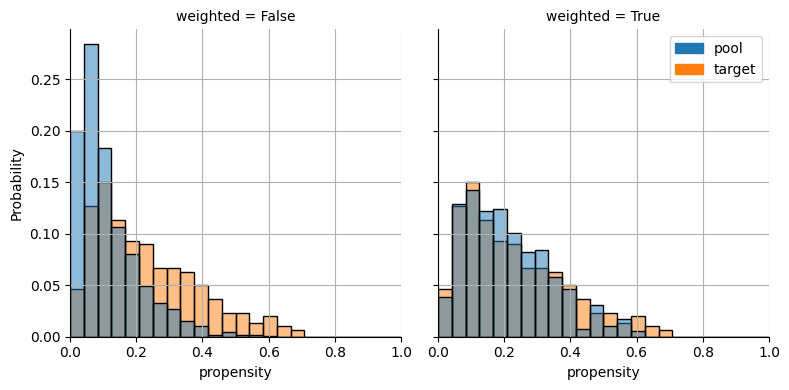

In [5]:
weighter.plot_propensity_score_distributions();

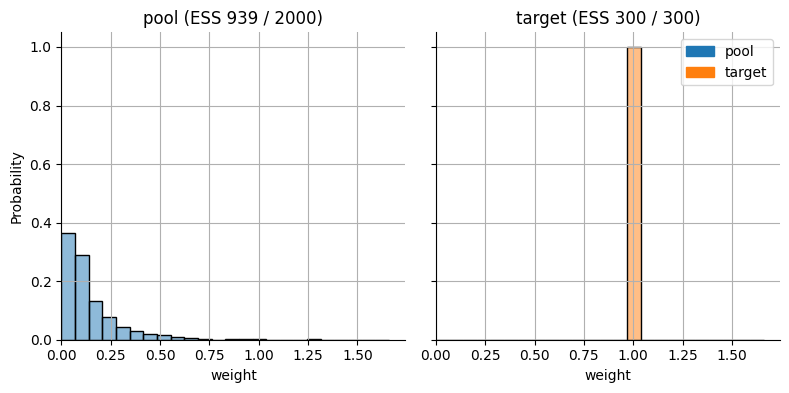

In [6]:
weighter.plot_weight_distributions();

To see the effect on the covariates themselves, put the unweighted pool, the weighted pool and the target into a single `MatchingData` -- the same trick the matching demos use to show "pool (prematch)" alongside "pool" and "target" -- and pass `weights=` through to `plot_numeric_features`/`plot_categoric_features`. The unweighted pool copy gets weight 1, so a single call draws all three distributions together.

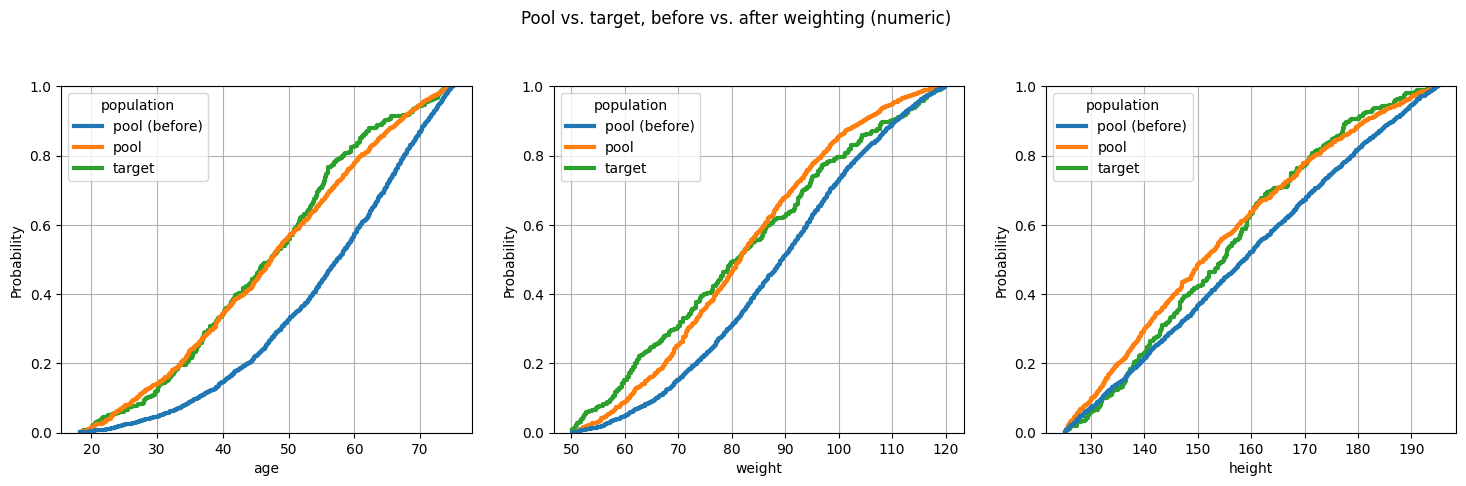

In [7]:
before_pool = matching_data.get_population(matching_data.pool_name).copy()
before_pool[weighter.weight_col] = 1.0

combined = matched.copy()
combined.append(before_pool, name="pool (before)")
hue_order = ["pool (before)", matching_data.pool_name, matching_data.target_name]

plot_numeric_features(
    combined, weights=weighter.weight_col, hue_order=hue_order, include_only=headers.numeric, col_wrap=3
)
plt.suptitle("Pool vs. target, before vs. after weighting (numeric)", y=1.05);

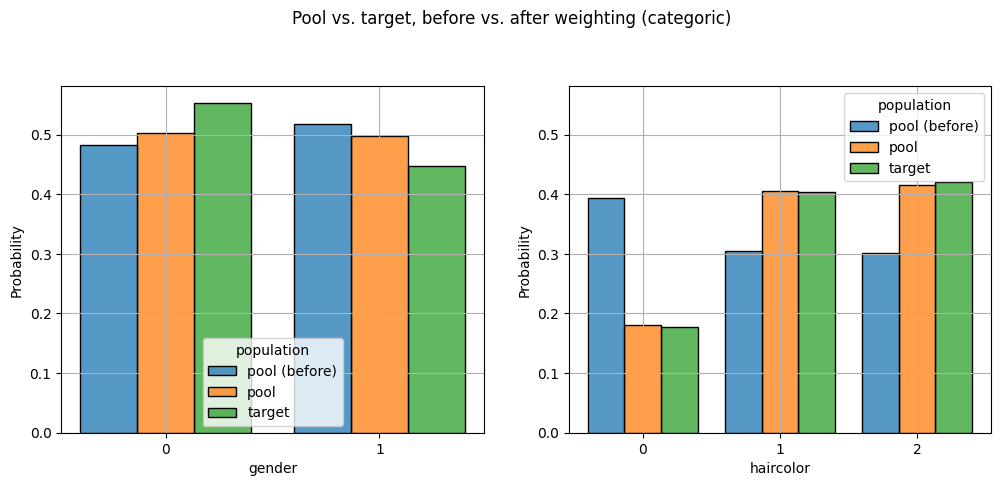

In [8]:
plot_categoric_features(
    combined, weights=weighter.weight_col, hue_order=hue_order, include_only=headers.categoric, col_wrap=2
)
plt.suptitle("Pool vs. target, before vs. after weighting (categoric)", y=1.05);

## Choosing a method: overlap weights

Different estimands trade fidelity to the target against stability. **Overlap weights** (Li, Morgan & Zaslavsky, 2018) weight each patient by the probability of belonging to the *other* population, so patients who could plausibly belong to either population are emphasized and those who clearly belong to just one are smoothly down-weighted. Weights are bounded in $[0, 1]$, so extreme weights cannot occur, at the price of targeting the overlap population rather than the target itself. Both populations are reweighted, so `weighted_balance_table()` compares the weighted pool to the weighted target.

Changing `method` is all it takes.

In [9]:
overlap = PropensityScoreWeighter(matching_data, objective="beta", method="overlap", max_iter=20, seed=0)
overlap_matched = overlap.match()

weighted_balance_table(overlap)

Training model LogisticRegression (iter 1/20, 0.0 s) ...


Best propensity score weights found (overlap):


	Model: LogisticRegression


	* C: 71.55682161754872


	* fit_intercept: True


...

Training model SGDClassifier (iter 17/20, 0.2 s) ...


Training model LogisticRegression (iter 18/20, 0.2 s) ...


Training model LogisticRegression (iter 19/20, 0.2 s) ...


Training model SGDClassifier (iter 20/20, 0.2 s) ...


,feature,moment,target,unweighted_pool,weighted_pool
0,gender_1.0,mean,0.500954,0.517000,0.500941
1,haircolor_1,mean,0.391011,0.304500,0.391003
2,haircolor_2,mean,0.403530,0.302000,0.403523
3,age,mean,48.897809,55.417328,48.898310
4,weight,mean,83.289065,88.704041,83.289283
5,height,mean,154.607092,159.050598,154.607253


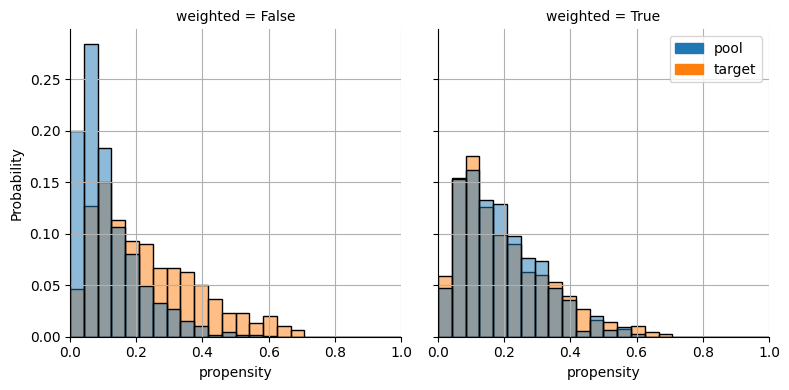

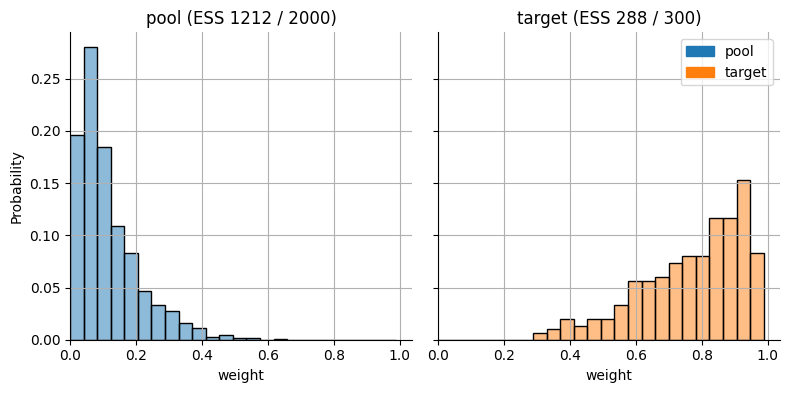

In [10]:
overlap.plot_propensity_score_distributions();
overlap.plot_weight_distributions();

### Reusing the propensity model: `match(method=...)`

The hyperparameter search is the expensive step, while a fitted propensity model can be mapped to any estimand cheaply. `match(method)` (and `get_weights(method)`, `score(method)`, `weighted_balance_table(weighter, method)` and the plot function) apply a different method to the fitted model without searching again and without changing the weighter. Keep in mind that the model was selected to optimize the balance of the method given at construction, so matching afresh with the method you intend to use (as above) is the more principled choice. Passing `method` is convenient for comparing estimands on the same model.

In [11]:
rows = []
for method in ["att", "atc", "ate", "overlap", "matching"]:
    w_pool = weighter.get_weights(method)
    rows.append(
        {
            "method": method,
            "balance (beta distance)": weighter.score(method),
            "pool ESS": effective_sample_size(w_pool),
            "target ESS": effective_sample_size(weighter.get_target_weights(method)),
            "max pool weight / mean": w_pool.max() / w_pool.mean(),
        }
    )
pd.DataFrame(rows).set_index("method").round(3)

,balance (beta distance),pool ESS,target ESS,max pool weight / mean
method,,,,
att,0.028,939.305,300.000,11.321
atc,0.113,2000.000,117.027,1.000
ate,0.096,1963.723,136.098,2.320
overlap,0.000,1211.869,288.163,5.401
matching,0.021,972.418,297.920,6.859


## Trimming extreme weights

The main practical failure mode of IPTW-style weights (`"att"`, `"atc"`, `"ate"`) is a small number of extreme weights, driven by patients whose covariates make the model almost certain they belong to one population. `trim_quantiles=(low, high)` clips each population's weights at the given quantiles before they are scored -- a standard bias/variance trade-off: a little exact balance is sacrificed in exchange for much more stable, lower-variance weights.

Training model LogisticRegression (iter 1/20, 0.0 s) ...


Best propensity score weights found (att):


	Model: LogisticRegression


	* C: 71.55682161754872


	* fit_intercept: True


...

Training model SGDClassifier (iter 17/20, 0.2 s) ...


Training model LogisticRegression (iter 18/20, 0.2 s) ...


Training model LogisticRegression (iter 19/20, 0.2 s) ...


Training model SGDClassifier (iter 20/20, 0.2 s) ...


Untrimmed: ESS=939.3, max weight=1.66
Trimmed:   ESS=1142.3, max weight=0.46, n_trimmed=200


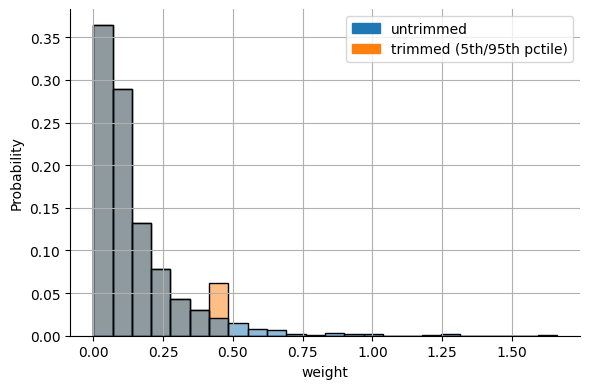

In [12]:
trimmed = PropensityScoreWeighter(
    matching_data, objective="beta", method="att", trim_quantiles=(0.05, 0.95), max_iter=20, seed=0
)
trimmed.match()

print(f"Untrimmed: ESS={weighter.effective_sample_size():.1f}, max weight={weighter.weights.max():.2f}")
print(f"Trimmed:   ESS={trimmed.effective_sample_size():.1f}, max weight={trimmed.weights.max():.2f}, n_trimmed={trimmed.diagnostics['n_trimmed']}")

labels = ["untrimmed", "trimmed (5th/95th pctile)"]
data = pd.concat(
    [
        pd.DataFrame({"weight": weighter.weights, "weights": labels[0]}),
        pd.DataFrame({"weight": trimmed.weights, "weights": labels[1]}),
    ]
)
g = sns.FacetGrid(data=data, height=4, aspect=1.5)
g.map_dataframe(
    sns.histplot,
    bins=24,
    binrange=(0, data["weight"].max()),
    x="weight",
    hue="weights",
    hue_order=labels,
    alpha=0.5,
    common_norm=False,
    stat="probability",
)
g.ax.grid(True)
plt.legend(
    handles=[
        matplotlib.patches.Patch(color=sns.color_palette()[i], label=label)
        for i, label in enumerate(labels)
    ]
);

## Takeaways

- Weighting keeps **every** pool patient, unlike the subset-selection matchers -- some patients just count for more or less.
- `PropensityScoreWeighter` follows the same philosophy as the matchers: a balance `objective` guides decisions, including the propensity model's hyperparameters, and `method` selects how propensity scores become weights.
- `method` is the estimand: `"att"` (IPTW), `"atc"`, `"ate"`, `"overlap"` or `"matching"`. Methods that also reweight the target (all but `"att"`) return target weights, which `weighted_balance_table()` takes into account.
- It requires a **patient-level** target -- there's no aggregate-only ("published Table 1") variant. Use `MAICWeighter` or `EntropyBalanceWeighter` for that.
- It does **not** solve for exact balance, so check `weighted_balance_table()` and `effective_sample_size()` on the fitted result. `min_ess_fraction` keeps the search from buying balance with a handful of dominant patients.
- `trim_quantiles` caps extreme weights, and `match(method=...)` compares estimands on a fitted propensity model without searching again.